# Mobile Device Activity, in Yogyakarta, Can Explain More Than You Think! Population Comparison and Weekday-Weekend Patterns.
1. Do subdistricts with more population equates to more asigned devices in that subdistrict?
2. Does the comparison between weekend and weekday of device activity in each subdistrict explain more about mobility?

Data: BPS 2021 population; JogjaPulse home-device assignments (Dec 2021–Apr 2022) and December 2021 hourly presence. Everything that I'm about to discuss here is just an interpretation of the data I analyzed and should not be taken as fact for every edge case scenario. Association is not causation.

In [ ]:
from pathlib import Path

print("Folder where Python is looking:")
print(Path.cwd())

excel_files = sorted(path.name for path in Path.cwd().glob("*.xlsx"))
print("\nExcel files in this folder:")
print("\n".join(excel_files) if excel_files else "No Excel files found.")

Folder where Python is looking:
C:\Users\M6NRK\Downloads

Excel files in this folder:
yogyakarta_complete_comparison.xlsx


In [ ]:
# Run this cell if packages are missing:
# %pip install pandas openpyxl numpy matplotlib seaborn scipy statsmodels
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120
DATA_FILE = Path("yogyakarta_complete_comparison.xlsx")
if not DATA_FILE.exists():
    DATA_FILE = Path("/mnt/data/yogyakarta_complete_comparison(1).xlsx")
assert DATA_FILE.exists(), f"Place the source Excel workbook beside this notebook: {DATA_FILE}"
OUT = Path("figures")
OUT.mkdir(exist_ok=True)
def savefig(name):
    plt.tight_layout()
    plt.savefig(OUT / name, dpi=180, bbox_inches="tight")
    plt.show()


In [ ]:
areas = pd.read_excel(DATA_FILE, sheet_name="Area comparison", dtype={"kapanewon_code":str})
profiles = pd.read_excel(DATA_FILE, sheet_name="Complete hourly profiles", dtype={"kapanewon_code":str})
notes = pd.read_excel(DATA_FILE, sheet_name="Method notes")
areas["population"] = pd.to_numeric(areas["population_2021"], errors="coerce")
areas["home_devices"] = pd.to_numeric(areas["home_devices_dec2021_apr2022"], errors="coerce")
areas["ratio_100"] = 100 * areas["home_devices"] / areas["population"]
areas["complete"] = areas["dec_complete_744"].astype(bool)
areas["area"] = areas["kapanewon"] + " (" + areas["kab_kota"] + ")"
df = areas.dropna(subset=["population", "home_devices"]).copy()
df = df[(df["population"] > 0) & (df["home_devices"] >= 0)].copy()
print(f"Population comparison: {len(df)} areas; complete hourly coverage: {df['complete'].sum()} areas")
# Display all subdistricts, rather than only the first five.
with pd.option_context("display.max_rows", None):
    display(
        df[
            [
                "area",
                "population",
                "home_devices",
                "ratio_100",
                "dec_hourly_coverage_pct",
            ]
        ]
    )
with pd.option_context("display.max_colwidth", None):
    display(notes)


Population comparison: 78 areas; complete hourly coverage: 39 areas


,area,population,home_devices,ratio_100,dec_hourly_coverage_pct
0,TEMON (KULON PROGO),28789,2330,8.093369,99.87
1,WATES (KULON PROGO),49444,7250,14.663053,100.00
2,PANJATAN (KULON PROGO),38850,1040,2.676963,90.99
3,GALUR (KULON PROGO),32491,1025,3.154720,97.18
4,LENDAH (KULON PROGO),40939,2177,5.317668,96.64
5,SENTOLO (KULON PROGO),50748,3367,6.634744,100.00
6,PENGASIH (KULON PROGO),53524,4441,8.297212,100.00
7,KOKAP (KULON PROGO),35831,3053,8.520555,99.73
8,GIRIMULYO (KULON PROGO),24421,1297,5.311003,95.43
9,NANGGULAN (KULON PROGO),30816,2714,8.807113,100.00


,Topic,Description
0,Home counts,"Distinct devices with estimated home in area across Dec 2021–Apr 2022, not residents"
1,Hourly presence,Distinct devices with >=1 GPS ping within the area-hour
2,Mean hourly counts,Average n_maids over published hourly slots; complete area comparisons use 744 slots
3,Normalized hourly index,"For each area and date: n_maids divided by its mean over 24 hours, then averaged by weekday/weekend and hour"
4,Coverage,Published December area-hour slots / 744
5,Outliers,"Flag ratio >100 or <2 devices per 100 residents; descriptive thresholds, not statistical tests"
6,No imputation,Suppressed hours are not treated as zero
7,Limitations,Device sample non-random; different time windows; hourly counts not additive; 39 complete areas selected
8,Source,"JogjaPulse README.md and BPS 2022 publications, population reference year 2021"


## 1. Population versus assigned home devices
Pearson measures linear association; Spearman measures monotonic association. The fitted regression line describes an association, not an allocation rule. Residuals indicate how far an observed device count is from its fitted value.

In [ ]:
# Keep the calculations needed by the later charts and analysis.
pearson_r, pearson_p = stats.pearsonr(df["population"], df["home_devices"])
spearman_r, spearman_p = stats.spearmanr(df["population"], df["home_devices"])

X = sm.add_constant(df["population"])
model = sm.OLS(df["home_devices"], X).fit()

df["predicted_devices"] = model.predict(X)
df["residual"] = df["home_devices"] - df["predicted_devices"]

influence = model.get_influence()
df["studentized_residual"] = influence.resid_studentized_external
df["regression_outlier"] = df["studentized_residual"].abs() > 2
df["ratio_flag"] = (df["ratio_100"] > 100) | (df["ratio_100"] < 2)

print(
    f"Pearson r={pearson_r:.3f} (p={pearson_p:.3g}); "
    f"Spearman rho={spearman_r:.3f} (p={spearman_p:.3g})"
)
print(
    f"OLS R²={model.rsquared:.3f}; "
    f"slope={model.params['population']:.4f} devices/person"
)

# Display the original Excel columns, rather than regression diagnostics.
columns_to_display = [
    "kab_kota",
    "kapanewon",
    "kapanewon_code",
    "population_2021",
    "home_devices_dec2021_apr2022",
    "home_devices_per_100_residents",
    "dec_hourly_rows",
    "dec_hourly_coverage_pct",
    "dec_complete_744",
]

# Use all source rows: no outlier filter and no .head().
# Keep df unchanged so later calculations and charts still work.
all_subdistricts = areas.loc[:, columns_to_display].copy()

# Number the displayed rows from 1 to 78.
all_subdistricts.index = pd.RangeIndex(
    start=1, stop=len(all_subdistricts) + 1, name="No."
)

print(f"\nDisplaying all {len(all_subdistricts)} subdistricts:")

# Prevent Pandas from hiding rows, columns, or long column names.
with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None,
    "display.max_colwidth", None,
):
    display(all_subdistricts)

Pearson r=0.720 (p=1.08e-13); Spearman rho=0.609 (p=3.35e-09)
OLS R²=0.519; slope=0.2211 devices/person

Displaying all 78 subdistricts:


,kab_kota,kapanewon,kapanewon_code,population_2021,home_devices_dec2021_apr2022,home_devices_per_100_residents,dec_hourly_rows,dec_hourly_coverage_pct,dec_complete_744
No.,,,,,,,,,
1,KULON PROGO,TEMON,34.01.01,28789,2330,8.093,743,99.87,False
2,KULON PROGO,WATES,34.01.02,49444,7250,14.663,744,100.00,True
3,KULON PROGO,PANJATAN,34.01.03,38850,1040,2.677,677,90.99,False
4,KULON PROGO,GALUR,34.01.04,32491,1025,3.155,723,97.18,False
5,KULON PROGO,LENDAH,34.01.05,40939,2177,5.318,719,96.64,False
6,KULON PROGO,SENTOLO,34.01.06,50748,3367,6.635,744,100.00,True
7,KULON PROGO,PENGASIH,34.01.07,53524,4441,8.297,744,100.00,True
8,KULON PROGO,KOKAP,34.01.08,35831,3053,8.521,742,99.73,False
9,KULON PROGO,GIRIMULYO,34.01.09,24421,1297,5.311,710,95.43,False


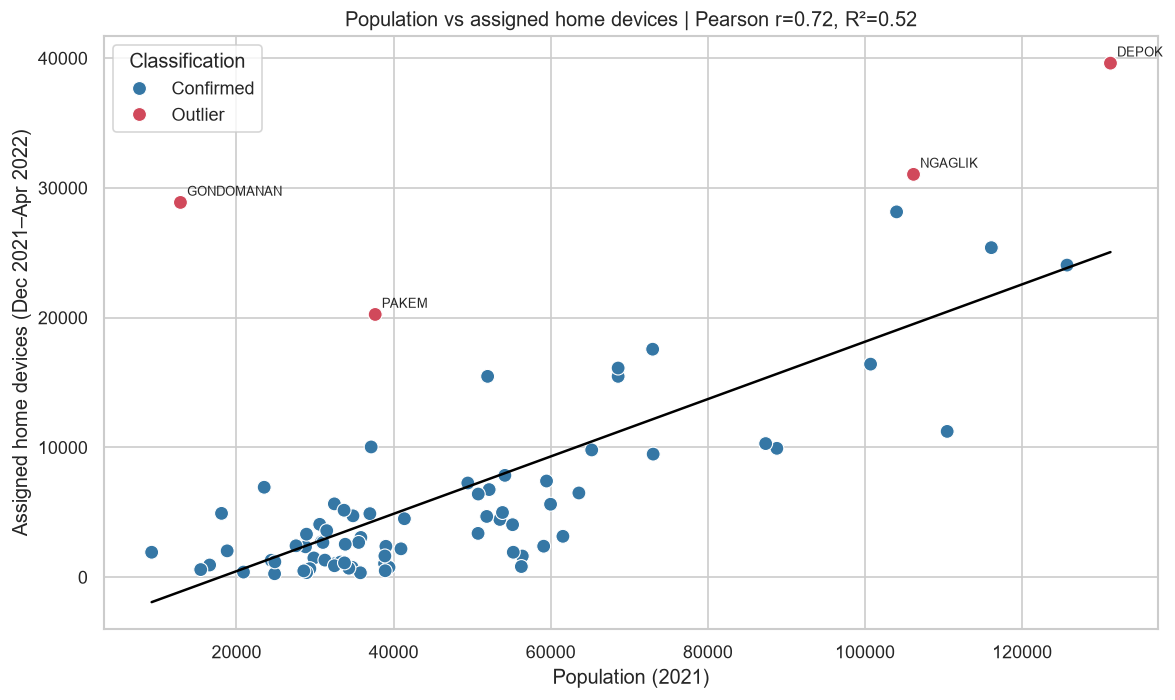

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))

# Plot the data using the existing Boolean outlier flags.
sns.scatterplot(
    data=df,
    x="population",
    y="home_devices",
    hue="regression_outlier",
    palette={False: "#3577a5", True: "#d1495b"},
    s=70,
    ax=ax,
)

# Draw the fitted regression line.
xs = np.linspace(df["population"].min(), df["population"].max(), 100)

ax.plot(
    xs,
    model.predict(sm.add_constant(xs)),
    color="black",
    label="OLS fit",
)

# Label the outlier subdistricts.
for _, row in df.loc[df["regression_outlier"]].iterrows():
    ax.annotate(
        row["kapanewon"],
        (row["population"], row["home_devices"]),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8,
    )

# Keep the existing title and axis labels.
ax.set(
    title=(
        "Population vs assigned home devices | "
        f"Pearson r={pearson_r:.2f}, R²={model.rsquared:.2f}"
    ),
    xlabel="Population (2021)",
    ylabel="Assigned home devices (Dec 2021–Apr 2022)",
)

# Change only the legend text, not the underlying data.
legend = ax.get_legend()

if legend is not None:
    legend.set_title("Classification")
    label_names = {"False": "Confirmed", "True": "Outlier"}

    for text in legend.get_texts():
        original_label = text.get_text()
        text.set_text(label_names.get(original_label, original_label))

# Save and display the updated chart using your existing helper.
savefig("01_population_vs_devices.png")


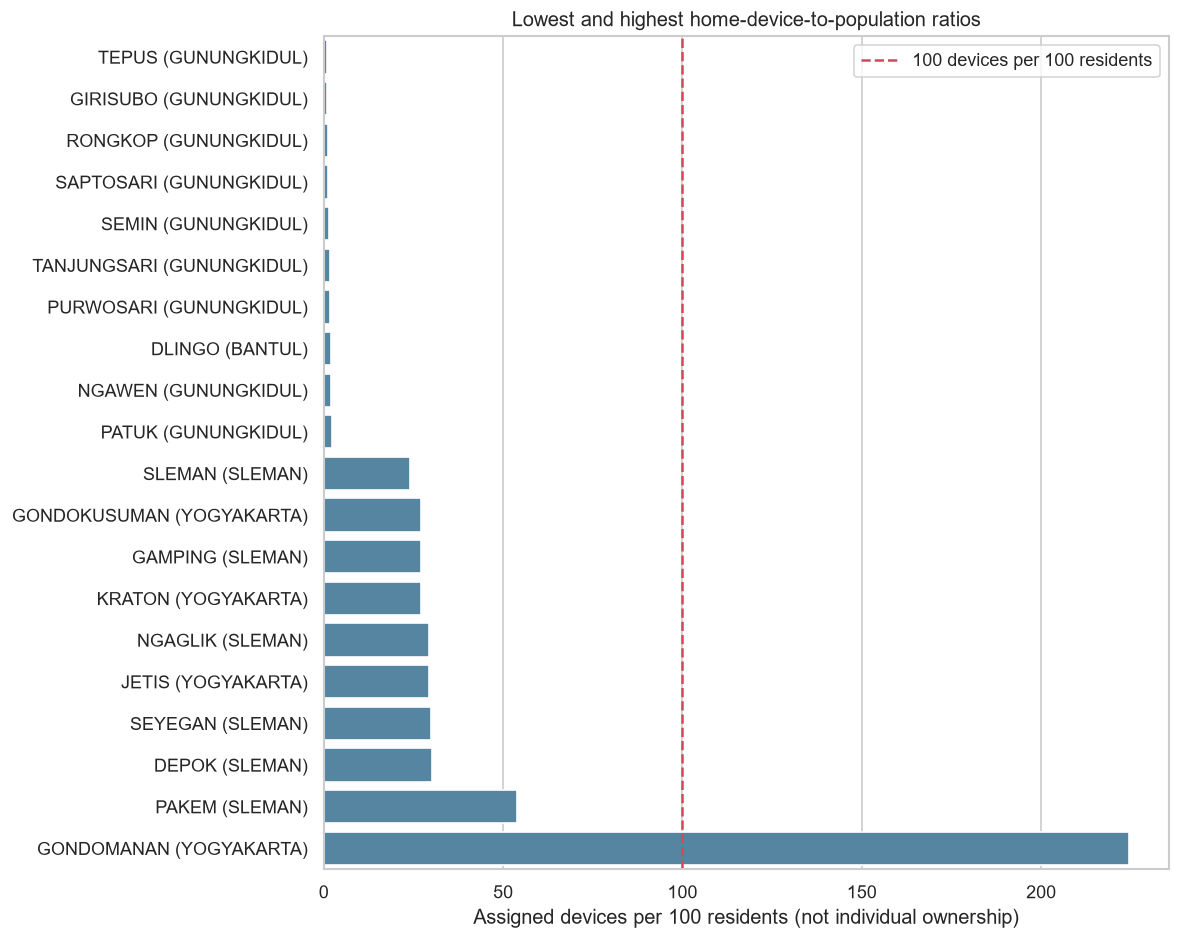

In [ ]:
extremes=pd.concat([df.nsmallest(10,"ratio_100"),df.nlargest(10,"ratio_100")]).drop_duplicates("kapanewon_code").sort_values("ratio_100")
fig,ax=plt.subplots(figsize=(10,8))
sns.barplot(data=extremes,y="area",x="ratio_100",color="#4888ae",ax=ax)
ax.axvline(100,color="#d1495b",ls="--",label="100 devices per 100 residents")
ax.set(title="Lowest and highest home-device-to-population ratios",
       xlabel="Assigned devices per 100 residents (not individual ownership)",ylabel="")
ax.legend()
savefig("03_device_population_ratios.png")


## 2. Weekday versus weekend device presence
For fair comparisons, restrict analysis to subdistricts with **all 744 December hourly slots**. The source workbook supplies weekday/weekend mean hourly presence for each area. We use paired comparisons because weekday and weekend values refer to the same subdistrict. These are descriptive aggregates, not raw independent hourly observations.

In [ ]:
complete=df[df["complete"]].copy()
complete["weekday"] = pd.to_numeric(complete["weekday_mean_hourly_devices_published"],errors="coerce")
complete["weekend"] = pd.to_numeric(complete["weekend_mean_hourly_devices_published"],errors="coerce")
complete=complete.dropna(subset=["weekday","weekend"])
complete["weekend_minus_weekday"] = complete["weekend"]-complete["weekday"]
complete["weekend_change_pct"] = np.where(complete["weekday"]>0,100*complete["weekend_minus_weekday"]/complete["weekday"],np.nan)
tstat,tp=stats.ttest_rel(complete["weekend"],complete["weekday"])
wstat,wp=stats.wilcoxon(complete["weekend"],complete["weekday"]) if (complete["weekend_minus_weekday"]!=0).any() else (np.nan,np.nan)
print(f"Complete areas n={len(complete)}")
print(f"Mean of area-level weekday means={complete['weekday'].mean():.2f}; weekend means={complete['weekend'].mean():.2f}")
print(f"Mean paired weekend-weekday difference={complete['weekend_minus_weekday'].mean():.2f} devices")
print(f"Paired t-test p={tp:.4g}; Wilcoxon signed-rank p={wp:.4g}")
print("Caution: these tests treat subdistricts as units; geographic dependence and selection may affect inference.")
display(complete[["area","weekday","weekend","weekend_change_pct"]].sort_values("weekend_change_pct").head(10))


Complete areas n=39
Mean of area-level weekday means=193.72; weekend means=186.35
Mean paired weekend-weekday difference=-7.37 devices
Paired t-test p=0.05596; Wilcoxon signed-rank p=0.1275
Caution: these tests treat subdistricts as units; geographic dependence and selection may affect inference.


,area,weekday,weekend,weekend_change_pct
65,JETIS (YOGYAKARTA),56.4022,38.1927,-32.285088
62,PAKEM (SLEMAN),406.3551,307.5417,-24.317007
72,KRATON (YOGYAKARTA),56.8388,45.0208,-20.792135
1,WATES (KULON PROGO),126.4547,102.9375,-18.597332
76,UMBULHARJO (YOGYAKARTA),242.4982,200.2760,-17.411346
66,GONDOKUSUMAN (YOGYAKARTA),134.6159,117.4740,-12.733934
73,GONDOMANAN (YOGYAKARTA),104.7971,91.6615,-12.534316
27,KASIHAN (BANTUL),412.6739,366.8073,-11.114490
52,MLATI (SLEMAN),241.0453,214.4948,-11.014735
50,MINGGIR (SLEMAN),99.3170,88.6042,-10.786472


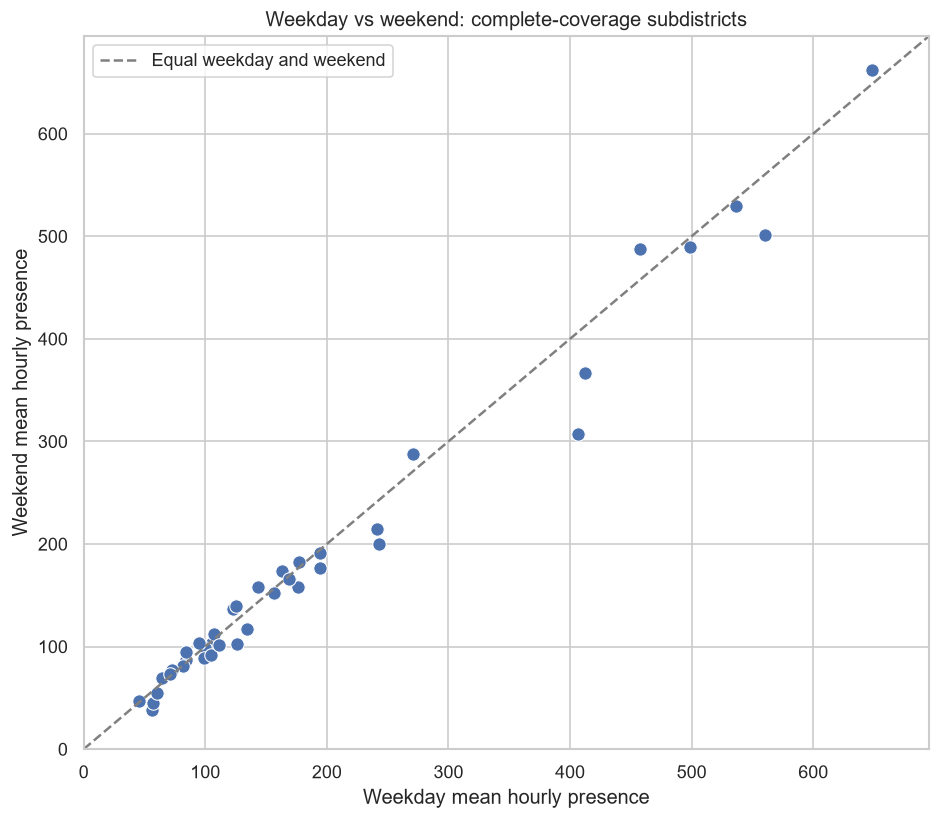

In [ ]:
fig,ax=plt.subplots(figsize=(8,7))
sns.scatterplot(data=complete,x="weekday",y="weekend",s=65,ax=ax)
lim=max(complete[["weekday","weekend"]].max())*1.05
ax.plot([0,lim],[0,lim],"--",color="gray",label="Equal weekday and weekend")
ax.set(xlim=(0,lim),ylim=(0,lim),xlabel="Weekday mean hourly presence",
       ylabel="Weekend mean hourly presence",title="Weekday vs weekend: complete-coverage subdistricts")
ax.legend()
savefig("04_weekday_vs_weekend_scatter.png")


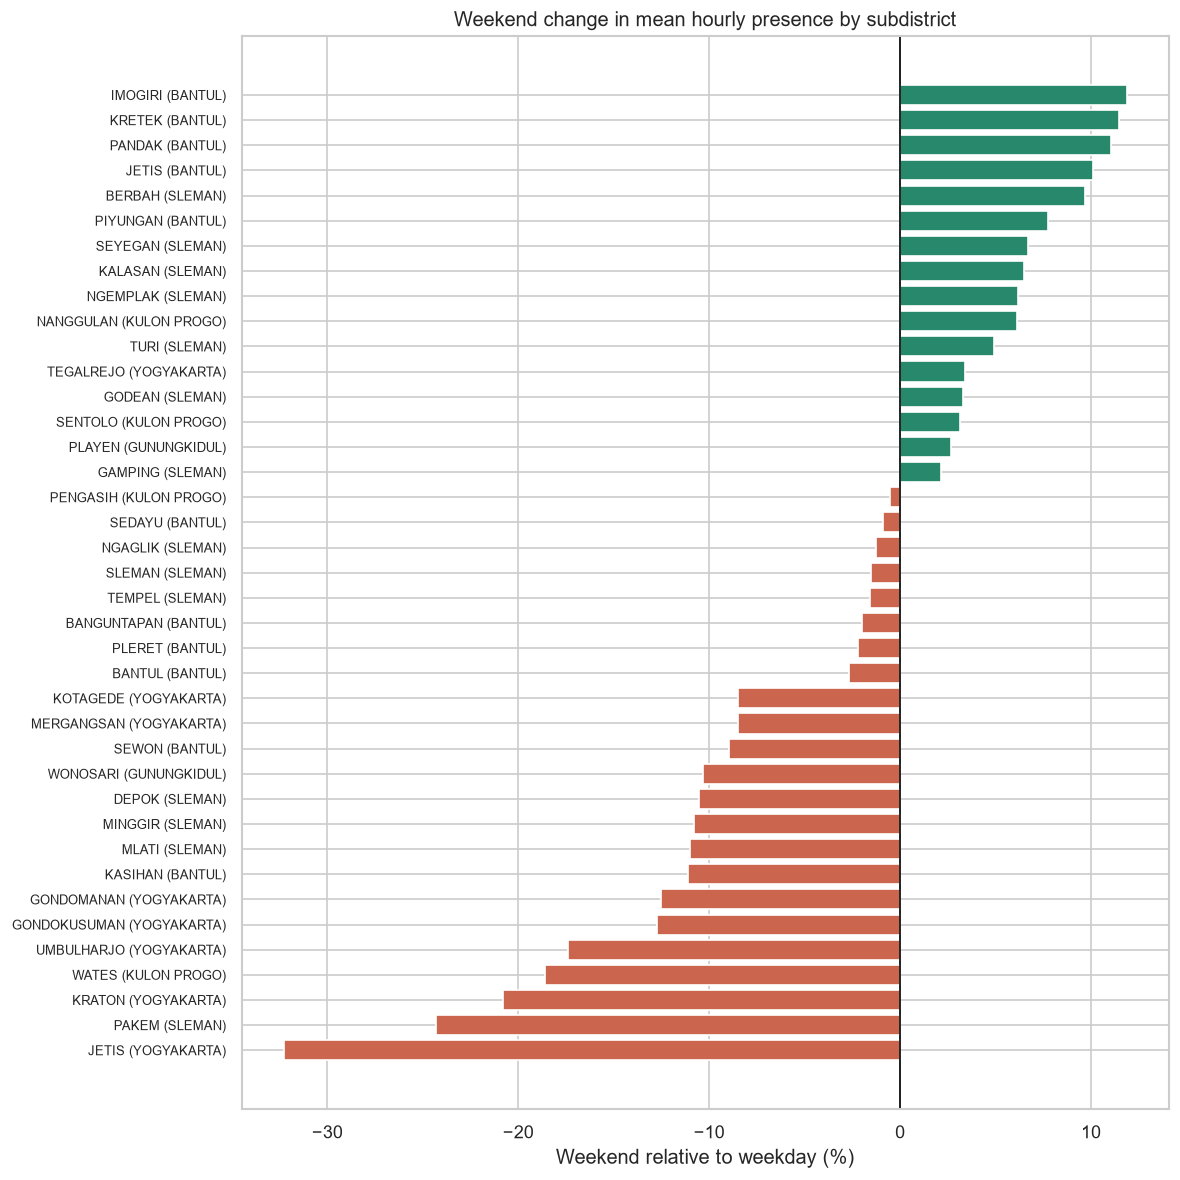

In [ ]:
ranked=complete.sort_values("weekend_change_pct")
fig,ax=plt.subplots(figsize=(10,10))
colors=np.where(ranked["weekend_change_pct"]>=0,"#27886b","#cb654d")
ax.barh(ranked["area"],ranked["weekend_change_pct"],color=colors)
ax.axvline(0,color="black",lw=1)
ax.set(title="Weekend change in mean hourly presence by subdistrict",
       xlabel="Weekend relative to weekday (%)",ylabel="")
ax.tick_params(axis="y",labelsize=8)
savefig("05_weekend_change_by_area.png")


### Hour-of-day profiles
The `Complete hourly profiles` worksheet provides average hourly device presence and a **daily-normalized activity index**. The index is useful for comparing *shape* of the daily cycle without larger subdistricts dominating the chart. Means across subdistricts are unweighted, so each complete area contributes equally.

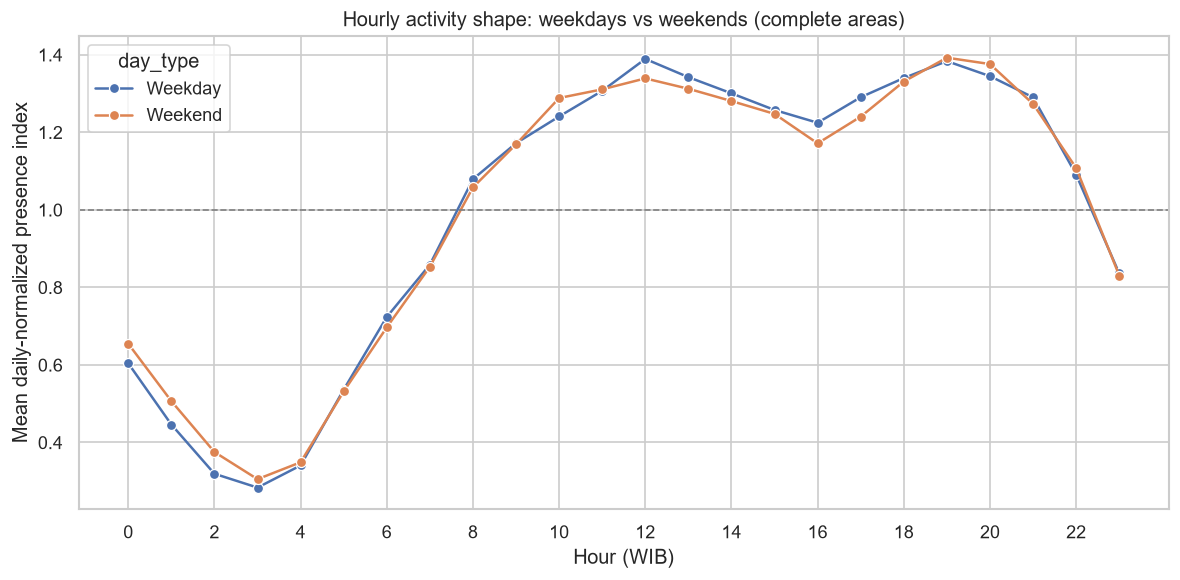

In [ ]:
profiles["hour_wib"]=pd.to_numeric(profiles["hour_wib"],errors="coerce")
profiles["mean_daily_normalized_index"]=pd.to_numeric(profiles["mean_daily_normalized_index"],errors="coerce")
hourly=(profiles.groupby(["day_type","hour_wib"],as_index=False)["mean_daily_normalized_index"].mean())
fig,ax=plt.subplots(figsize=(10,5))
sns.lineplot(data=hourly,x="hour_wib",y="mean_daily_normalized_index",hue="day_type",
             marker="o",ax=ax)
ax.axhline(1,color="gray",ls="--",lw=1)
ax.set(xticks=range(0,24,2),xlabel="Hour (WIB)",ylabel="Mean daily-normalized presence index",
       title="Hourly activity shape: weekdays vs weekends (complete areas)")
savefig("06_hourly_normalized_profiles.png")


## 3. Connecting the questions: do activity patterns contextualize population–device outliers?
Join the two datasets using the official subdistrict code. A positive residual means **more home-assigned devices than the population-based regression predicts**; a weekend uplift means **more hourly presence on weekends**. A relationship between these is exploratory, not a causal explanation.

In [ ]:
linked=df.merge(complete[["kapanewon_code","weekday","weekend","weekend_change_pct"]],
                     on="kapanewon_code",how="left",validate="one_to_one")
linked["outlier_group"]=np.where(linked["regression_outlier"],"Regression outlier","Other area")
print("Outliers with complete hourly data:",int((linked["regression_outlier"] & linked["weekend_change_pct"].notna()).sum()),
      "of",int(linked["regression_outlier"].sum()))
display(linked.loc[linked["regression_outlier"] | linked["ratio_flag"],
                   ["area","ratio_100","residual","studentized_residual","complete","weekend_change_pct"]]
        .sort_values("studentized_residual",key=abs,ascending=False))


Outliers with complete hourly data: 4 of 4


,area,ratio_100,residual,studentized_residual,complete,weekend_change_pct
73,GONDOMANAN (YOGYAKARTA),224.368638,29995.541018,6.735022,True,-12.534316
62,PAKEM (SLEMAN),53.752390,15882.965812,2.942399,True,-24.317007
53,DEPOK (SLEMAN),30.180125,14562.236832,2.883674,True,-10.554212
58,NGAGLIK (SLEMAN),29.233421,11533.152789,2.152355,True,-1.271909
40,SEMIN (GUNUNGKIDUL),1.441522,-7659.755257,-1.359734,False,NaN
43,SAPTOSARI (GUNUNGKIDUL),1.253532,-4151.672903,-0.730660,False,NaN
22,DLINGO (BANTUL),1.918100,-3990.669086,-0.702081,False,NaN
35,TEPUS (GUNUNGKIDUL),0.922561,-3611.102779,-0.635359,False,NaN
41,NGAWEN (GUNUNGKIDUL),1.991254,-2933.135032,-0.515780,False,NaN
39,RONGKOP (GUNUNGKIDUL),1.179115,-2085.797290,-0.367048,False,NaN


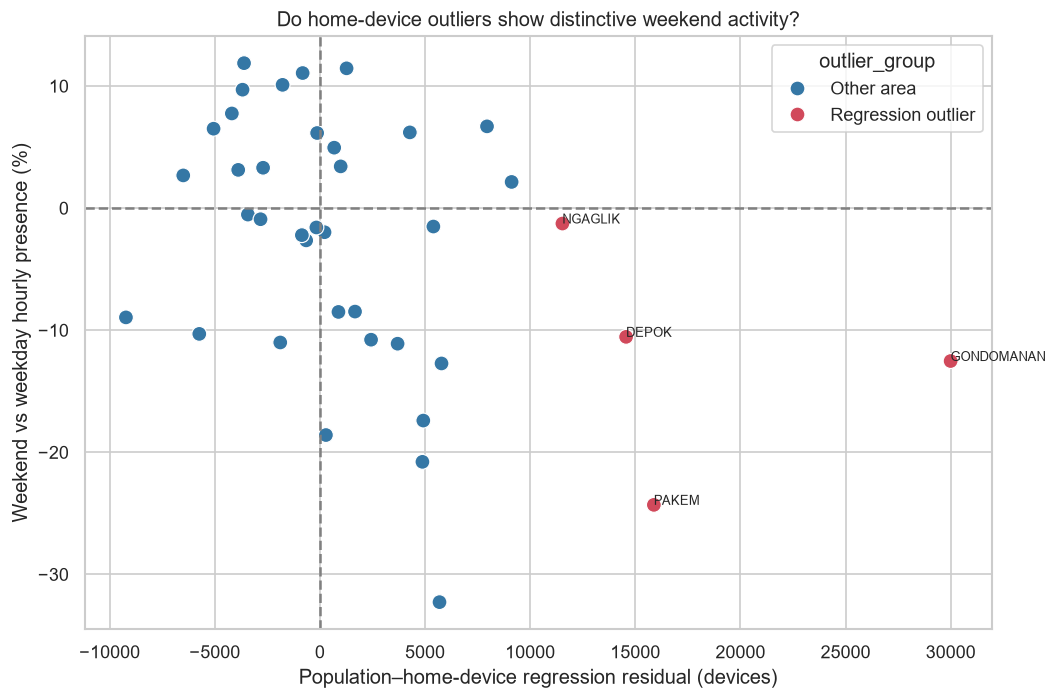

Exploratory Spearman correlation (residual vs weekend change): rho=-0.426, p=0.00689, n=39


In [ ]:
subset=linked.dropna(subset=["weekend_change_pct"]).copy()
fig,ax=plt.subplots(figsize=(9,6))
sns.scatterplot(data=subset,x="residual",y="weekend_change_pct",hue="outlier_group",
                palette={"Regression outlier":"#d1495b","Other area":"#3577a5"},s=80,ax=ax)
ax.axvline(0,color="gray",ls="--");ax.axhline(0,color="gray",ls="--")
for _,row in subset.loc[subset["regression_outlier"]].iterrows():
    ax.annotate(row["kapanewon"],(row["residual"],row["weekend_change_pct"]),fontsize=8)
ax.set(xlabel="Population–home-device regression residual (devices)",
       ylabel="Weekend vs weekday hourly presence (%)",
       title="Do home-device outliers show distinctive weekend activity?")
savefig("07_outliers_vs_weekend_change.png")
if len(subset)>=3:
    rr,pp=stats.spearmanr(subset["residual"],subset["weekend_change_pct"])
    print(f"Exploratory Spearman correlation (residual vs weekend change): rho={rr:.3f}, p={pp:.3g}, n={len(subset)}")


## 4. Automated interpretation and limitations
The cells below report numerical answers from the source file after execution. Interpret associations conservatively; weekday/weekend patterns can provide context but cannot demonstrate why devices are assigned to a location.

In [ ]:
direction="positive" if pearson_r>0 else "negative"
significance="statistically detectable" if pearson_p<0.05 else "not statistically detectable at 5%"
weekend_dir="higher" if complete["weekend_minus_weekday"].mean()>0 else "lower"
outliers=df.loc[df["regression_outlier"],"area"].tolist()
display(Markdown(f'''
### Research question 1
Across **{len(df)} subdistricts**, population and assigned home devices show a **{direction}** linear association
(Pearson **r = {pearson_r:.3f}**).
The OLS model has **R² = {model.rsquared:.3f}**; the association is **{significance}**.
However, there are some outliers:
**{", ".join(outliers) if outliers else "none flagged"}**.

### Research question 2
Among **{len(complete)} complete-coverage subdistricts**, weekend mean hourly presence is, on average,
**{weekend_dir}** than weekday presence by **{abs(complete["weekend_minus_weekday"].mean()):.2f} devices** per subdistrict-hour.
Although, it should be noted that, a difference in weekend/weekday device presence does **not** by itself explain home-device assignment.

### Caveats
- Assigned *home devices* (Dec 2021–Apr 2022) are not necessarily representing the count of people or explain the exact ownership rates of devices.
- Hourly *presence* (December 2021) includes devices that are present in the subdistrict.
- Only **{len(complete)}** complete-coverage areas enter the primary weekday/weekend comparison, which might not represent the overall population.
- In the border between districts may detect overlapping hours of device usagevand neighboring areas may be dependent; p-values are descriptive/exploratory.
- Different observation periods and non-random device sampling prevent causal attribution.
'''))



### Research question 1
Across **78 subdistricts**, population and assigned home devices show a **positive** linear association
(Pearson **r = 0.720**).
The OLS model has **R² = 0.519**; the association is **statistically detectable**.
However, there are some outliers:
**DEPOK (SLEMAN), NGAGLIK (SLEMAN), PAKEM (SLEMAN), GONDOMANAN (YOGYAKARTA)**.

### Research question 2
Among **39 complete-coverage subdistricts**, weekend mean hourly presence is, on average,
**lower** than weekday presence by **7.37 devices** per subdistrict-hour.
Although, it should be noted that, a difference in weekend/weekday device presence does **not** by itself explain home-device assignment.

### Caveats
- Assigned *home devices* (Dec 2021–Apr 2022) are not necessarily representing the count of people or explain the exact ownership rates of devices.
- Hourly *presence* (December 2021) includes devices that are present in the subdistrict.
- Only **39** complete-coverage areas enter the primary weekday/weekend comparison, which might not represent the overall population.
- Missing/suppressed hourly slots are **not zero** and are not imputed.
- Repeated hours and neighboring areas may be dependent; p-values are descriptive/exploratory.
- Different observation periods and non-random device sampling prevent causal attribution.
